In [2]:
import numpy as np
import os, sys
import warnings
warnings.filterwarnings("ignore")
from influxdb import InfluxDBClient
import operator
import onnxruntime as ort
from time import sleep
from datetime import datetime, timezone
import pytz
from scipy.signal import butter, lfilter, filtfilt, resample_poly
sys.path.append('/home/jiayu/SeismoApnea4Ubicomp_Feb/Code')
sys.path.append('/home/jiayu/SeismoApnea4Ubicomp_Feb')
import yaml
import matplotlib.pyplot as plt
from scipy.signal import find_peaks


raw_Z shape: (14551,), raw_Y shape: (14551,), raw_X shape: (14551,), raw_THO shape: (14551,), raw_ABD shape: (14551,)


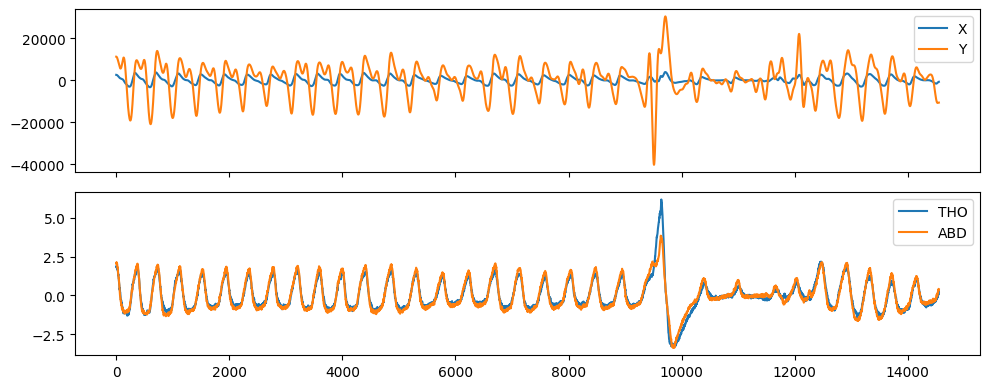

In [ ]:

def low_pass_filter(data, Fs, low, order):
	b, a = butter(order, low/(Fs * 0.5), 'low')

	if data.ndim == 1:
		N = len(data)
		padded = np.pad(data, (N, N), mode='reflect')
	elif data.ndim == 2:
		N = data.shape[1]
		padded = np.pad(data, ((0, 0), (N, N)), mode='reflect')
	
	filtered_data = filtfilt(b, a, padded)

	if data.ndim == 1:
		filtered_data = filtered_data[N:-N]
	elif data.ndim == 2:
		filtered_data = filtered_data[:, N:-N]
	
	return filtered_data


def normalize(data):
	data = (data - np.mean(data, axis=1, keepdims=True)) / np.std(data, axis=1, keepdims=True)
	return data


def read_influx(influx, unit, table_name, data_name, start_timestamp, end_timestamp):
	if influx['ip'] == '127.0.0.1' or influx['ip'] == 'localhost':
		client = InfluxDBClient(influx['ip'], '8086', influx['user'], influx['passw'], influx['db'],  ssl=influx['ssl'])
	else:
		client = InfluxDBClient(influx['ip'].split('//')[1], '8086', influx['user'], influx['passw'], influx['db'],  ssl=influx['ssl'])
	query = 'SELECT "' + data_name + '" FROM "' + table_name + '" WHERE "location" = \''+unit+'\' AND time >= '+ str(int(start_timestamp*10e8))+' AND time < '+str(int(end_timestamp*10e8))
	result = client.query(query)
	points = list(result.get_points())
	values =  list(map(operator.itemgetter(data_name), points))
	times  =  list(map(operator.itemgetter('time'),  points))
	data = np.array(values)
	return data, times


def connect_influxdb(influxdb_conf):
	url_str = influxdb_conf["ip"].split("://")
	if len(url_str) >= 2:
		ssl_val = True if url_str[0] == "https" else False
		url_ip = url_str[1]
	else:
		ssl_val = True
		url_ip = url_str[0]
	# print(f'url_ip: {url_ip}')
	verify = False

	influxdb_client = InfluxDBClient(url_ip, influxdb_conf["port"], influxdb_conf["user"], influxdb_conf["password"],
									 influxdb_conf["db"], ssl=ssl_val, verify_ssl=verify)

	try:
		if influxdb_client.ping():
			print(f"Successfully connected to the Influxdb! {url_ip}")
		else:
			print(f"Failed to connect to the Influxdb {url_ip} , exit")
			exit(1)
	except Exception as e:
		print(f"Ping failure, Connection to the Influxdb {url_ip} failed!, exit")
		exit(1)
	return influxdb_client


if __name__ == "__main__":
	influx_vitals_bsg = {'ip': 'https://sensorserver.engr.uga.edu', 'db': 'shake', 'user': 'algtest', 'passw': 'sensorweb711', 'ssl': True}
	
	influx_vitals_psg = {'ip': 'https://sensorserver.engr.uga.edu', 'db': 'sleeplab', 'user': 'algtest', 'passw': 'sensorweb711', 'ssl': True}
	

	# id 23, room 2
	# # back, Y clear, X not clear
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1743822957422&to=1743823056668&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1743820980466&to=1743821030605&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	
	# # prone, Y and X clear, and sycronized
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1743828935468&to=1743829101289&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	
	# # right, Y and X clear, and unsycronized
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1743832691761&to=1743832875592&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1743839238296&to=1743839322966&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1743840339006&to=1743840423676&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	

	# id 30, room 2

	# left, Y and X clear, and unsycronized
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1744599462867&to=1744599599690&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1744596171174&to=1744596362840&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1744595978073&to=1744596063743&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# back, Y and X clear, and sycronized
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1744605051698&to=1744605287288&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1744605522878&to=1744605758468&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	
	# back 2, Y and X clear, and sycronized
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1744616322000&to=1744616558000&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	
	# right
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1744612722000&to=1744612958000&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	

	# id 50, room 2
	# left, Y and X clear, and unsycronized
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1746328500949&to=1746328736078&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1746332023405&to=1746332254390&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1746342024949&to=1746342523432&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	# right
	# url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom2/sleep-lab-tri-axis-monitoring-room-2?orgId=1&from=1746346912298&to=1746347057807&var-mac=b8:27:eb:ab:e3:b7&var-name=vitalsigns'
	
	
	
	
	mac = url.split('var-mac=')[1].split('&')[0]
	start_time = int(url.split('from=')[1].split('&')[0]) / 1000
	end_time = int(url.split('to=')[1].split('&')[0]) / 1000


	start_time_bsg = start_time
	end_time_bsg = end_time

	start_time_psg = start_time
	end_time_psg = end_time


	raw_Z, _ = read_influx(influx_vitals_bsg, unit=mac, table_name='Z', 
						data_name="value", start_timestamp=start_time_bsg, end_timestamp=end_time_bsg)
	raw_Y, _ = read_influx(influx_vitals_bsg, unit=mac, table_name='N', 
						data_name="value", start_timestamp=start_time_bsg, end_timestamp=end_time_bsg)
	raw_X, _ = read_influx(influx_vitals_bsg, unit=mac, table_name='E', 
						data_name="value", start_timestamp=start_time_bsg, end_timestamp=end_time_bsg)
	raw_THO, _ = read_influx(influx_vitals_psg, unit=mac, table_name='SleepLab_test', 
						data_name="Effort THO", start_timestamp=start_time_psg, end_timestamp=end_time)
	raw_ABD, _ = read_influx(influx_vitals_psg, unit=mac, table_name='SleepLab_test', 
						data_name="Effort ABD", start_timestamp=start_time_psg, end_timestamp=end_time)
	
	X = low_pass_filter(raw_X, 100, 1, 3)
	Y = low_pass_filter(raw_Y, 100, 1, 3)
	# X = (X - np.mean(X)) / np.std(X)
	# Y = (Y - np.mean(Y)) / np.std(Y)
	X = X - np.mean(X)
	Y = Y - np.mean(Y)
	THO = (raw_THO - np.mean(raw_THO)) / np.std(raw_THO)
	ABD = (raw_ABD - np.mean(raw_ABD)) / np.std(raw_ABD)
	print(f'raw_Z shape: {raw_Z.shape}, raw_Y shape: {raw_Y.shape}, raw_X shape: {raw_X.shape}, raw_THO shape: {raw_THO.shape}, raw_ABD shape: {raw_ABD.shape}')
	
	peaks_x, _ = find_peaks(X, distance=100, height=np.quantile(X, 0.99))
	peaks_abd, _ = find_peaks(ABD, distance=100, height=np.quantile(ABD, 0.99))


	fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
	axes[0].plot(X, label='X')
	axes[0].plot(Y, label='Y')
	axes[0].legend()

	axes[1].plot(THO, label='THO')
	axes[1].plot(ABD, label='ABD')
	axes[1].legend()
	plt.tight_layout()
	plt.show()